# Risk Analysis Notebook
## 📦 1. Libraries & Configuration

We begin by importing all the libraries needed for this project and setting up global visual styles.

| Library | Purpose |
|---------|---------|
| `pandas` | Data manipulation and analysis |
| `numpy` | Numerical computing and array operations |
| `matplotlib` | Base plotting library |
| `seaborn` | Statistical data visualization |
| `sqlite3` | Lightweight SQL database (built into Python) |
| `sklearn` | Machine learning models and evaluation tools |

We also define a consistent color palette to be used across all visualizations throughout the notebook.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sqlite3
import warnings

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style("whitegrid")

BLUE   = "#1F4E79"
RED    = "#C0392B"
GREEN  = "#1E8449"
ORANGE = "#E67E22"
LIGHT  = "#2E75B6"

print("✅ Libraries loaded")

✅ Libraries loaded


## 📂 2. Load & Inspect the Dataset

We load the raw dataset and perform an initial inspection to understand its structure before any processing.

**Dataset:** [Give Me Some Credit — Kaggle](https://www.kaggle.com/c/GiveMeSomeCredit)  
**Size:** ~150,000 U.S. bank clients  
**Target variable:** `SeriousDlqin2yrs` — whether the client experienced serious financial distress in the next 2 years (1 = yes, 0 = no)

> 💡 **Why this dataset?** It represents a real-world credit scoring problem used by financial institutions to assess loan risk. Each row is one client. Each column is a behavioral or financial attribute.


In [ ]:
df = pd.read_csv('data/cs-training.csv', index_col=0)

print(f"Shape: {df.shape}")
print(f"\nColumnas y tipos de dato:")
print(df.dtypes)
print(f"\nPrimeras 5 filas:")
df.head()

Shape: (150000, 11)

Columnas y tipos de dato:
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

Primeras 5 filas:


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 🔍 3. Data Quality Assessment

Before cleaning, we systematically assess the quality of the data across three dimensions:

1. **Missing values** — which columns have nulls and how many
2. **Duplicate rows** — are there any identical records?
3. **Class balance** — how evenly distributed is the target variable?

> 💡 **Why class balance matters in ML:** If 95% of clients did NOT default, a model that always predicts "no default" would be 95% accurate — without learning anything useful. This is called the **class imbalance problem** and requires special handling.


In [ ]:
print("=" * 55)
print("ANÁLISIS DE CALIDAD DE DATOS")
print("=" * 55)

# Valores nulos
nulls = df.isnull().sum()
null_pct = (nulls / len(df) * 100).round(2)
null_df = pd.DataFrame({'Nulos': nulls, '% del total': null_pct})
null_df = null_df[null_df['Nulos'] > 0]

print(f"\n📌 Columnas con valores nulos:")
print(null_df)

# Duplicados
dupes = df.duplicated().sum()
print(f"\n📌 Filas duplicadas: {dupes}")

# Balance de clases
target_counts = df['SeriousDlqin2yrs'].value_counts()
target_pct = (target_counts / len(df) * 100).round(2)
print(f"\n📌 Balance de la variable objetivo:")
print(pd.DataFrame({'Conteo': target_counts, '%': target_pct}))

# Estadísticas descriptivas
print(f"\n📌 Estadísticas descriptivas:")
df.describe().T

ANÁLISIS DE CALIDAD DE DATOS

📌 Columnas con valores nulos:
                    Nulos  % del total
MonthlyIncome       29731        19.82
NumberOfDependents   3924         2.62

📌 Filas duplicadas: 609

📌 Balance de la variable objetivo:
                  Conteo      %
SeriousDlqin2yrs               
0                 139974  93.32
1                  10026   6.68

📌 Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


## 🧹 4. Data Cleaning & Feature Engineering

We address the data quality issues identified in the previous step and prepare the dataset for analysis.

**Cleaning decisions:**

| Issue | Decision | Reason |
|-------|----------|--------|
| `MonthlyIncome` nulls (19.82%) | Fill with **median** | Median is robust to outliers unlike mean |
| `NumberOfDependents` nulls | Fill with **median** | Same rationale |
| `age = 0` | Remove rows | Age of 0 is a data entry error |
| `RevolvingUtilization > 1` | Remove rows | Credit utilization is a ratio — cannot exceed 100% |

> 💡 **Why median and not mean?** Income distributions are right-skewed — a few very high earners pull the mean upward. The median (middle value) better represents the "typical" client and is not affected by extremes.

We also rename all columns to shorter, snake_case names for cleaner code throughout the rest of the notebook.


In [ ]:
print(f"Shape antes de limpiar: {df.shape}")

# 1. Rellenar nulos — reasignando explícitamente (sin inplace)
median_income = df['MonthlyIncome'].median()
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(median_income)
print(f"✅ MonthlyIncome rellenado con mediana: ${median_income:,.0f}")

median_dep = df['NumberOfDependents'].median()
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(median_dep)
print(f"✅ NumberOfDependents rellenado con mediana: {median_dep}")

# 2. Filtrar errores
df = df[df['age'] > 0].copy()
df = df[df['RevolvingUtilizationOfUnsecuredLines'] <= 1].copy()

# 3. Renombrar columnas
df = df.rename(columns={
    'SeriousDlqin2yrs':                          'default',
    'RevolvingUtilizationOfUnsecuredLines':       'credit_utilization',
    'NumberOfTime30-59DaysPastDueNotWorse':       'late_30_59',
    'NumberOfTime60-89DaysPastDueNotWorse':       'late_60_89',
    'NumberOfTimes90DaysLate':                    'late_90plus',
    'NumberOfOpenCreditLinesAndLoans':            'open_credit_lines',
    'NumberRealEstateLoansOrLines':               'real_estate_loans',
    'NumberOfDependents':                         'dependents',
    'MonthlyIncome':                              'monthly_income',
    'DebtRatio':                                  'debt_ratio'
})

print(f"\nShape final: {df.shape}")
print(f"Nulos restantes: {df.isnull().sum().sum()}")
print(f"\n✅ Dataset limpio y listo para análisis")

Shape antes de limpiar: (150000, 11)
✅ MonthlyIncome rellenado con mediana: $5,400
✅ NumberOfDependents rellenado con mediana: 0.0

Shape final: (146678, 11)
Nulos restantes: 0

✅ Dataset limpio y listo para análisis


## 📊 5. Target Variable Distribution

We visualize the distribution of our target variable — `default` — to quantify the class imbalance before modeling.

**Understanding the imbalance:**
- A **15:1 ratio** means for every client who defaulted, there are ~15 who did not
- This is considered **severe imbalance** in machine learning
- Standard accuracy metrics become misleading — a model predicting "no default" 100% of the time would achieve ~93% accuracy without learning anything

> 💡 **How we handle this:** In the ML phase, we use `class_weight='balanced'` which instructs the model to penalize errors on the minority class (default = 1) proportionally more — effectively telling the model "missing a default is much more costly than a false alarm."


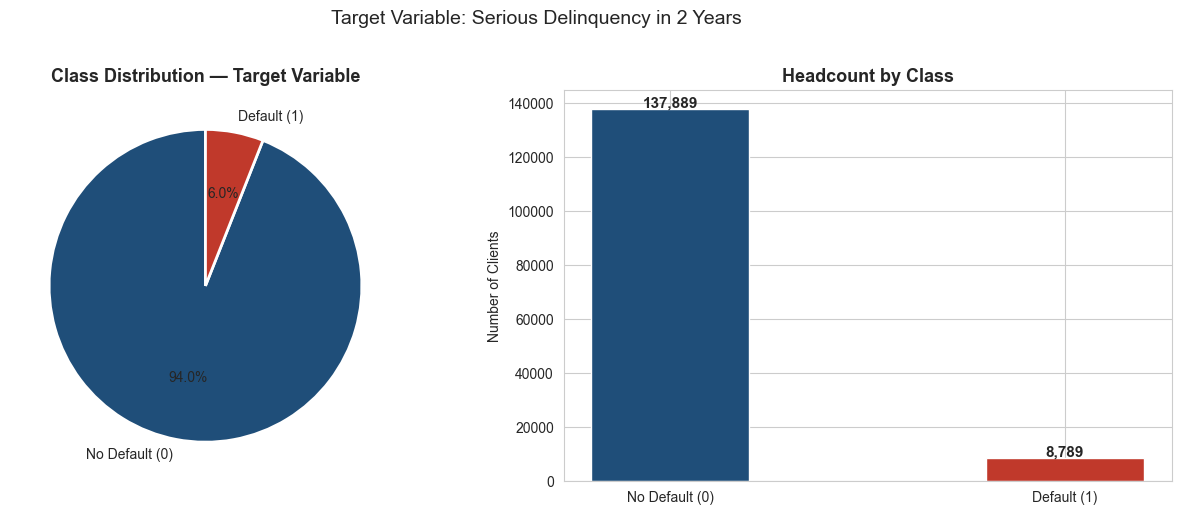


📌 Default rate: 5.99%
📌 No default: 137,889 clientes
📌 Default:    8,789 clientes
📌 Ratio desbalance: 15.7:1


In [ ]:
import os
os.makedirs('img', exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = df['default'].value_counts()
labels = ['No Default (0)', 'Default (1)']
colors = [BLUE, RED]

axes[0].pie(counts, labels=labels, autopct='%1.1f%%',
            colors=colors, startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Class Distribution — Target Variable', fontsize=13, fontweight='bold')

bars = axes[1].bar(labels, counts.values, color=colors, edgecolor='white', width=0.4)
axes[1].set_title('Headcount by Class', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Clients')
for bar, v in zip(bars, counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 500,
                 f'{v:,}', ha='center', fontsize=11, fontweight='bold')

plt.suptitle('Target Variable: Serious Delinquency in 2 Years',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('img/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

default_rate = df['default'].mean() * 100
print(f"\n📌 Default rate: {default_rate:.2f}%")
print(f"📌 No default: {counts[0]:,} clientes")
print(f"📌 Default:    {counts[1]:,} clientes")
print(f"📌 Ratio desbalance: {counts[0]/counts[1]:.1f}:1")

## 📈 6. Distribution of Numerical Features

We visualize the distribution of all key numerical features to identify skewness, outliers, and data characteristics that will inform preprocessing decisions.

**What we look for:**
- **Skewness:** Is the distribution symmetric or does it have a long tail?
- **Mean vs. Median gap:** A large gap signals the presence of outliers pulling the mean
- **Range:** Are there extreme values that could distort the model?

> 💡 **Right-skewed distributions** (long tail to the right) are common in financial data — most clients have moderate values, but a few have extreme ones. Variables like `monthly_income` and `debt_ratio` will require a **log transformation** before ML to normalize their distribution.


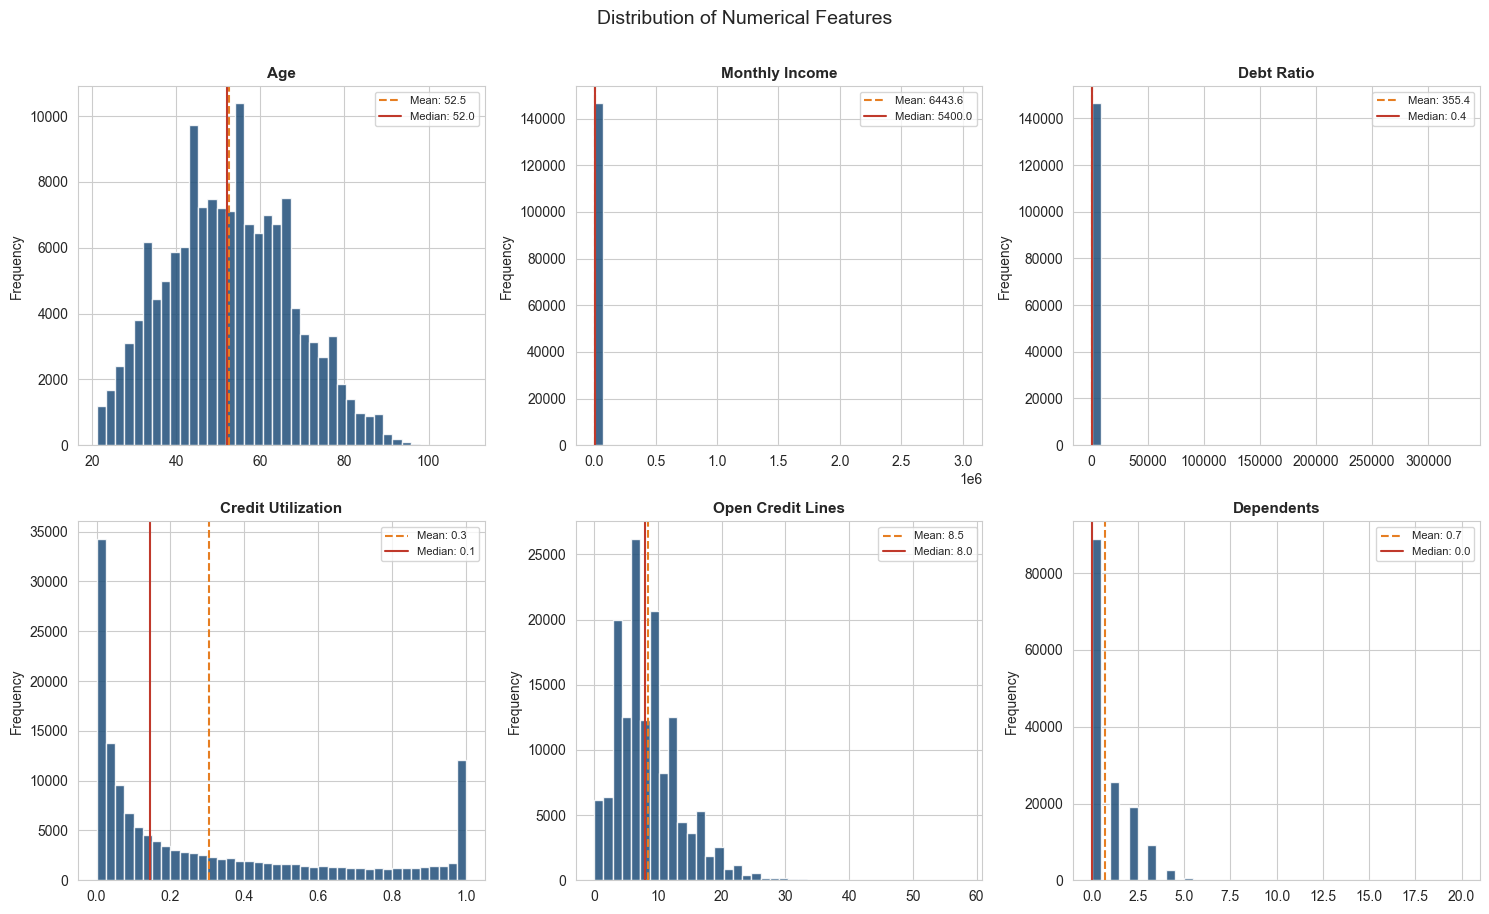

In [ ]:
numeric_cols = ['age', 'monthly_income', 'debt_ratio', 
                'credit_utilization', 'open_credit_lines', 'dependents']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    data = df[col].dropna()
    
    axes[i].hist(data, bins=40, color=BLUE, edgecolor='white', alpha=0.85)
    axes[i].axvline(data.mean(),   color=ORANGE, linewidth=1.5, 
                    linestyle='--', label=f'Mean: {data.mean():.1f}')
    axes[i].axvline(data.median(), color=RED,    linewidth=1.5, 
                    linestyle='-',  label=f'Median: {data.median():.1f}')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=8)

plt.suptitle('Distribution of Numerical Features', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('img/02_feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 🔗 7. Correlation Matrix

We compute Pearson correlations between all numerical features to understand linear relationships in the data — and specifically, which features are most associated with default.

**Reading the heatmap:**
- Values close to **+1**: strong positive correlation (both variables increase together)
- Values close to **-1**: strong negative correlation (one increases as the other decreases)
- Values close to **0**: no linear relationship

> ⚠️ **Important limitation:** Correlation only captures linear relationships. A feature might be highly predictive of default through a non-linear pattern that correlation misses entirely. This is one reason we use Random Forest later — it captures non-linear interactions automatically.


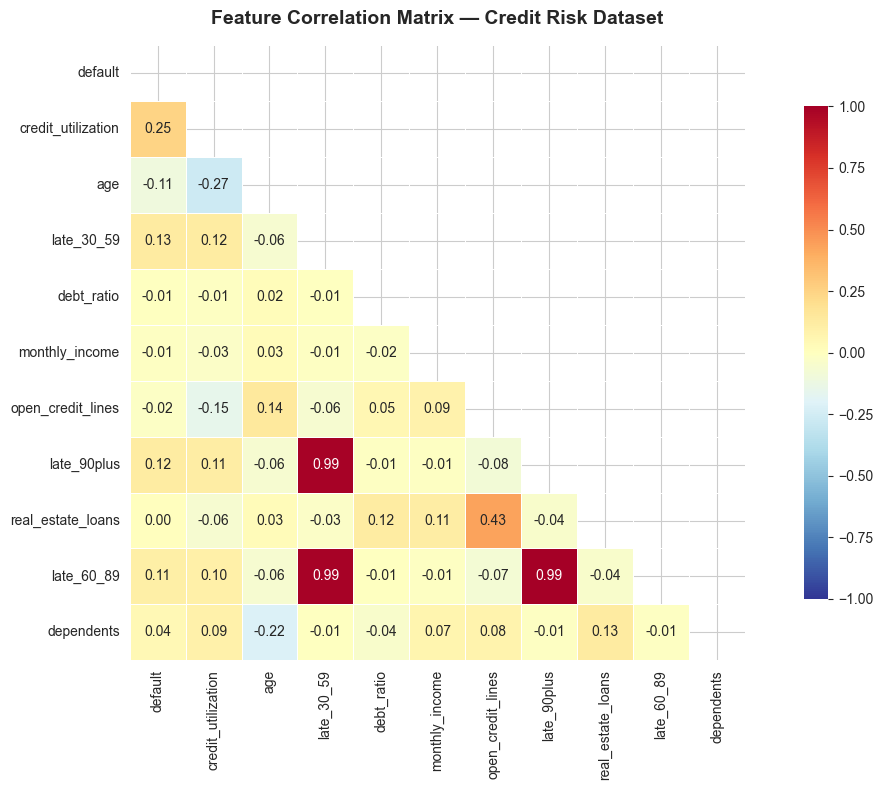


📌 Correlaciones más fuertes con 'default':
   credit_utilization: 0.249 (↑ positiva)
   late_30_59: 0.125 (↑ positiva)
   late_90plus: 0.118 (↑ positiva)
   age: -0.106 (↓ negativa)
   late_60_89: 0.105 (↑ positiva)


In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))

corr = df.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr,
            mask=mask,
            annot=True,
            fmt='.2f',
            cmap='RdYlBu_r',
            center=0,
            vmin=-1, vmax=1,
            square=True,
            linewidths=0.5,
            ax=ax,
            cbar_kws={'shrink': 0.8})

ax.set_title('Feature Correlation Matrix — Credit Risk Dataset',
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('img/03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Correlaciones más fuertes con 'default':")
corr_target = corr['default'].drop('default').sort_values(key=abs, ascending=False)
for col, val in corr_target.head(5).items():
    direction = "↑ positiva" if val > 0 else "↓ negativa"
    print(f"   {col}: {val:.3f} ({direction})")

## 📦 8. Feature Distribution by Default Status

We use boxplots to compare the distribution of key features between clients who defaulted and those who did not.

**How to read a boxplot:**
- The **line** inside the box = median
- The **box** edges = 25th and 75th percentile (middle 50% of data)
- The **whiskers** = range of non-outlier values
- The **dots** = outliers

> 💡 If the boxes of the two classes (default = 0 and default = 1) are clearly separated, it means that feature has strong discriminating power — it will be useful for the ML model. If they overlap heavily, the feature alone is not sufficient to separate the classes.


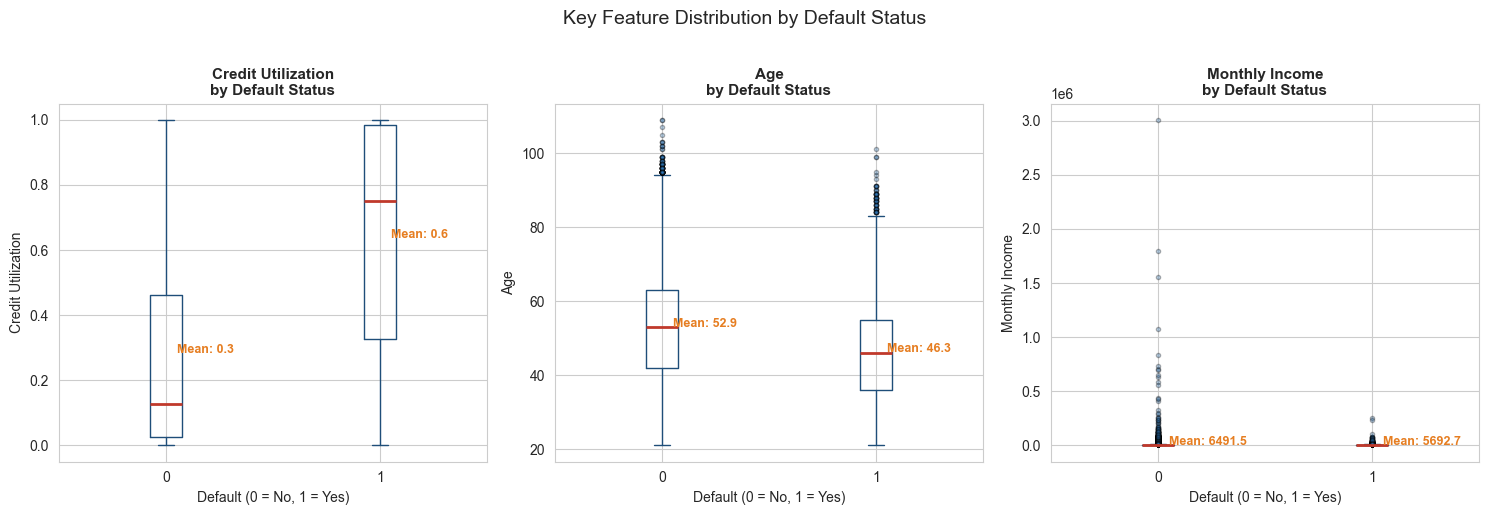


📌 Medias por clase:
         credit_utilization    age  monthly_income
default                                           
0                      0.28  52.88         6491.47
1                      0.64  46.30         5692.71


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Variables más correlacionadas con default
vars_to_plot = ['credit_utilization', 'age', 'monthly_income']

for i, var in enumerate(vars_to_plot):
    df.boxplot(column=var, by='default', ax=axes[i],
               boxprops=dict(color=BLUE),
               medianprops=dict(color=RED, linewidth=2),
               whiskerprops=dict(color=BLUE),
               capprops=dict(color=BLUE),
               flierprops=dict(marker='o', markerfacecolor=LIGHT,
                               markersize=3, alpha=0.3))
    
    axes[i].set_title(f'{var.replace("_", " ").title()}\nby Default Status',
                      fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Default (0 = No, 1 = Yes)')
    axes[i].set_ylabel(var.replace('_', ' ').title())
    
    # Calcular y mostrar medias
    means = df.groupby('default')[var].mean()
    for j, (cls, mean_val) in enumerate(means.items()):
        axes[i].annotate(f'Mean: {mean_val:.1f}',
                        xy=(j + 1, mean_val),
                        xytext=(8, 0), textcoords='offset points',
                        fontsize=9, color=ORANGE, fontweight='bold')

plt.suptitle('Key Feature Distribution by Default Status', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('img/04_boxplots_by_default.png', dpi=150, bbox_inches='tight')
plt.show()

# Resumen estadístico
print("\n📌 Medias por clase:")
print(df.groupby('default')[vars_to_plot].mean().round(2))

---
## 🗄️ PHASE 3 — SQL Analysis

---

## 9. Loading Data into SQLite

Before running SQL queries, we persist the cleaned DataFrame into a SQLite database.

**Why SQLite?**
- Built into Python — no installation or server required
- Entire database lives in a single `.db` file
- Fully compatible with standard SQL syntax
- Can be opened and queried with SQLite Viewer in VS Code

> 💡 In a real business environment, this data would already live in a corporate database (PostgreSQL, Snowflake, BigQuery). We simulate that workflow here using SQLite. The analytical SQL patterns demonstrated — aggregations, CASE WHEN, CTEs, window functions — are identical across all SQL engines.


In [ ]:
conn = sqlite3.connect('credit_risk.db')
df.to_sql('credit_risk', conn, if_exists='replace', index=False)
conn.close()

print(f"✅ Datos cargados en credit_risk.db")
print(f"   Tabla: credit_risk")
print(f"   Filas: {len(df):,}")
print(f"   Columnas: {len(df.columns)}")
print(f"\nColumnas disponibles para SQL:")
for col in df.columns:
    print(f"   - {col}")

✅ Datos cargados en credit_risk.db
   Tabla: credit_risk
   Filas: 146,678
   Columnas: 11

Columnas disponibles para SQL:
   - default
   - credit_utilization
   - age
   - late_30_59
   - debt_ratio
   - monthly_income
   - open_credit_lines
   - late_90plus
   - real_estate_loans
   - late_60_89
   - dependents


## 📋 10. SQL — Portfolio KPI Queries (Basic)

We run three business-focused SQL queries directly from Python using `pd.read_sql()`, which executes a query and returns the result as a DataFrame.

**Queries in this section:**

| Query | Business Question |
|-------|-----------------|
| Q1 | What are our baseline portfolio KPIs? |
| Q2 | Which age group has the highest default rate? |
| Q3 | Does debt level correlate with default rate? |

> 💡 **`AVG(default) * 100` as default rate:** Since `default` is a binary column (0 or 1), its average equals the proportion of 1s — the default rate. Multiplying by 100 converts it to a percentage. This is a standard SQL trick that avoids subqueries.

> 💡 **`CASE WHEN` for segmentation:** We use CASE WHEN to group continuous variables (age, debt ratio) into business-meaningful bands. This is the SQL equivalent of `pd.cut()` in pandas and is one of the most frequently used patterns in business intelligence queries.


In [ ]:
conn = sqlite3.connect('credit_risk.db')

q1 = """
SELECT
    COUNT(*)                                        AS total_clients,
    SUM("default")                                  AS total_defaults,
    ROUND(AVG("default") * 100, 2)                  AS default_rate_pct,
    ROUND(AVG(monthly_income), 0)                   AS avg_monthly_income,
    ROUND(AVG(debt_ratio), 2)                       AS avg_debt_ratio,
    ROUND(AVG(age), 1)                              AS avg_age
FROM credit_risk;
"""

q2 = """
SELECT
    CASE
        WHEN age < 30              THEN '1. <30'
        WHEN age BETWEEN 30 AND 40 THEN '2. 30-40'
        WHEN age BETWEEN 41 AND 50 THEN '3. 41-50'
        WHEN age BETWEEN 51 AND 60 THEN '4. 51-60'
        ELSE                            '5. 60+'
    END                                             AS age_band,
    COUNT(*)                                        AS clients,
    SUM("default")                                  AS defaults,
    ROUND(AVG("default") * 100, 2)                  AS default_rate_pct,
    ROUND(AVG(monthly_income), 0)                   AS avg_income
FROM credit_risk
GROUP BY age_band
ORDER BY age_band;
"""

q3 = """
SELECT
    CASE
        WHEN debt_ratio < 0.2  THEN '1. Low (<0.2)'
        WHEN debt_ratio < 0.4  THEN '2. Medium (0.2-0.4)'
        WHEN debt_ratio < 0.6  THEN '3. High (0.4-0.6)'
        ELSE                        '4. Very High (>0.6)'
    END                                             AS debt_band,
    COUNT(*)                                        AS clients,
    ROUND(AVG("default") * 100, 2)                  AS default_rate_pct,
    ROUND(AVG(monthly_income), 0)                   AS avg_income
FROM credit_risk
GROUP BY debt_band
ORDER BY debt_band;
"""

print("=" * 55)
print("QUERY 1 — KPIs Generales")
print("=" * 55)
print(pd.read_sql(q1, conn).to_string(index=False))

print("\n" + "=" * 55)
print("QUERY 2 — Default Rate por Rango de Edad")
print("=" * 55)
print(pd.read_sql(q2, conn).to_string(index=False))

print("\n" + "=" * 55)
print("QUERY 3 — Default Rate por Nivel de Deuda")
print("=" * 55)
print(pd.read_sql(q3, conn).to_string(index=False))

conn.close()

QUERY 1 — KPIs Generales
 total_clients  total_defaults  default_rate_pct  avg_monthly_income  avg_debt_ratio  avg_age
        146678            8789              5.99              6444.0          355.45     52.5

QUERY 2 — Default Rate por Rango de Edad
age_band  clients  defaults  default_rate_pct  avg_income
  1. <30     8395       892             10.63      3391.0
2. 30-40    25268      2179              8.62      5628.0
3. 41-50    34140      2555              7.48      7072.0
4. 51-60    34195      1929              5.64      7308.0
  5. 60+    44680      1234              2.76      6337.0

QUERY 3 — Default Rate por Nivel de Deuda
          debt_band  clients  default_rate_pct  avg_income
      1. Low (<0.2)    41360              5.43      7388.0
2. Medium (0.2-0.4)    37484              5.02      7438.0
  3. High (0.4-0.6)    21029              7.00      6391.0
4. Very High (>0.6)    46805              6.82      4836.0


## 🔬 11. SQL — Advanced Queries with CTEs & Window Functions

We apply advanced SQL techniques to build a multi-factor risk scoring system and rank clients by default risk.

**Common Table Expressions (CTEs):**  
A CTE (`WITH ... AS`) creates a named temporary result set within a query. It improves readability by breaking complex logic into named steps — similar to defining an intermediate variable in Python.

**Window Functions:**  
Unlike `GROUP BY` which collapses rows into groups, window functions compute a value for each row while "looking at" a related set of rows.

> 💡 **The SQL risk score** assigns points for each risk factor: late payments get more weight than low income because behavioral signals (paying late) are more predictive than static attributes (income level). This logic mirrors how FICO scores work in practice.


In [ ]:
conn = sqlite3.connect('credit_risk.db')

# ── Query 4: Default rate por rango de ingresos ───────────
q4 = """
SELECT
    CASE
        WHEN monthly_income < 3000  THEN '1. Low (<3K)'
        WHEN monthly_income < 6000  THEN '2. Medium (3K-6K)'
        WHEN monthly_income < 10000 THEN '3. High (6K-10K)'
        ELSE                             '4. Very High (>10K)'
    END                                             AS income_band,
    COUNT(*)                                        AS clients,
    ROUND(AVG("default") * 100, 2)                  AS default_rate_pct,
    ROUND(AVG(debt_ratio), 2)                       AS avg_debt_ratio,
    ROUND(AVG(credit_utilization), 2)               AS avg_credit_util
FROM credit_risk
GROUP BY income_band
ORDER BY income_band;
"""

# ── Query 5: Perfil del cliente de alto riesgo con CTE ────
q5 = """
WITH risk_scored AS (
    SELECT *,
        (CASE WHEN credit_utilization > 0.75  THEN 2 ELSE 0 END +
         CASE WHEN late_30_59 > 0             THEN 2 ELSE 0 END +
         CASE WHEN late_90plus > 0            THEN 3 ELSE 0 END +
         CASE WHEN debt_ratio > 0.5           THEN 1 ELSE 0 END +
         CASE WHEN monthly_income < 3000      THEN 1 ELSE 0 END +
         CASE WHEN age < 30                   THEN 1 ELSE 0 END
        )                                           AS risk_score
    FROM credit_risk
)
SELECT
    CASE
        WHEN risk_score >= 6 THEN '🔴 Critical'
        WHEN risk_score >= 4 THEN '🟡 High'
        WHEN risk_score >= 2 THEN '🟠 Medium'
        ELSE                      '🟢 Low'
    END                                             AS risk_level,
    COUNT(*)                                        AS clients,
    ROUND(AVG("default") * 100, 2)                  AS actual_default_rate_pct,
    ROUND(AVG(monthly_income), 0)                   AS avg_income,
    ROUND(AVG(age), 1)                              AS avg_age,
    ROUND(AVG(credit_utilization), 2)               AS avg_credit_util
FROM risk_scored
GROUP BY risk_level
ORDER BY actual_default_rate_pct DESC;
"""

# ── Query 6: Ranking de clientes por riesgo (Window Function)
q6 = """
WITH risk_scored AS (
    SELECT
        rowid                                       AS client_id,
        age,
        monthly_income,
        credit_utilization,
        late_90plus,
        debt_ratio,
        "default",
        (CASE WHEN credit_utilization > 0.75  THEN 2 ELSE 0 END +
         CASE WHEN late_30_59 > 0             THEN 2 ELSE 0 END +
         CASE WHEN late_90plus > 0            THEN 3 ELSE 0 END +
         CASE WHEN debt_ratio > 0.5           THEN 1 ELSE 0 END +
         CASE WHEN monthly_income < 3000      THEN 1 ELSE 0 END +
         CASE WHEN age < 30                   THEN 1 ELSE 0 END
        )                                           AS risk_score
    FROM credit_risk
)
SELECT
    client_id,
    age,
    monthly_income,
    credit_utilization,
    late_90plus,
    risk_score,
    "default"                                       AS actual_default,
    RANK() OVER (ORDER BY risk_score DESC)          AS risk_rank,
    ROUND(risk_score * 100.0 / 10, 0)              AS risk_score_pct
FROM risk_scored
WHERE risk_score >= 6
ORDER BY risk_rank
LIMIT 15;
"""

print("=" * 55)
print("QUERY 4 — Default Rate por Nivel de Ingresos")
print("=" * 55)
print(pd.read_sql(q4, conn).to_string(index=False))

print("\n" + "=" * 55)
print("QUERY 5 — Perfil del Cliente por Nivel de Riesgo (CTE)")
print("=" * 55)
print(pd.read_sql(q5, conn).to_string(index=False))

print("\n" + "=" * 55)
print("QUERY 6 — Top Clientes de Mayor Riesgo (Window Function)")
print("=" * 55)
print(pd.read_sql(q6, conn).to_string(index=False))

conn.close()

QUERY 4 — Default Rate por Nivel de Ingresos
        income_band  clients  default_rate_pct  avg_debt_ratio  avg_credit_util
       1. Low (<3K)    22516              8.01          138.82             0.37
  2. Medium (3K-6K)    71846              6.24          681.94             0.30
   3. High (6K-10K)    32792              5.22            0.33             0.29
4. Very High (>10K)    19524              4.07            0.28             0.26

QUERY 5 — Perfil del Cliente por Nivel de Riesgo (CTE)
risk_level  clients  actual_default_rate_pct  avg_income  avg_age  avg_credit_util
🔴 Critical     4855                    43.27      4158.0     43.6             0.87
    🟡 High     9965                    20.70      4840.0     44.6             0.77
  🟠 Medium    34676                     7.92      5584.0     48.8             0.49
     🟢 Low    97182                     1.93      7029.0     55.1             0.16

QUERY 6 — Top Clientes de Mayor Riesgo (Window Function)
 client_id  age  monthly_i

---
## 🤖 PHASE 4 — Machine Learning

---

## 12. Preprocessing for Machine Learning

Before training any model, we must prepare the data in three steps: transform skewed features, split into train/test sets, and scale all features to the same range.

**Step 1 — Log transformation:**  
Variables with extreme right skew (`monthly_income`, `debt_ratio`) are transformed using `log1p(x) = log(1 + x)`. This compresses large values and brings the distribution closer to normal.

**Step 2 — Stratified train/test split:**  
We split 80% for training and 20% for testing. The `stratify=y` parameter ensures both splits maintain the original default rate.

**Step 3 — StandardScaler:**  
Rescales each feature to mean=0, std=1 to prevent features with large numeric ranges from dominating the model.

> ⚠️ **Data leakage prevention:** The scaler is fitted only on training data and then applied to test data. Fitting on test data would leak information — an invalid and overoptimistic evaluation setup.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
import numpy as np

# ── 1. Separar features y variable objetivo ───────────────
X = df.drop(columns=['default'])
y = df['default']

print(f"Features (X): {X.shape}")
print(f"Target  (y): {y.shape}")
print(f"\nColumnas usadas como features:")
for col in X.columns:
    print(f"   - {col}")

# ── 2. Transformación logarítmica de variables sesgadas ───
skewed_cols = ['monthly_income', 'debt_ratio']

for col in skewed_cols:
    X[col] = np.log1p(X[col])
    
print(f"\n✅ Transformación log1p aplicada a: {skewed_cols}")

# ── 3. Train / Test Split ─────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\n✅ Split completado:")
print(f"   Train: {X_train.shape[0]:,} filas ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   Test:  {X_test.shape[0]:,} filas ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\n   Default rate en train: {y_train.mean()*100:.2f}%")
print(f"   Default rate en test:  {y_test.mean()*100:.2f}%")

# ── 4. Escalar features ───────────────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"\n✅ Features escaladas con StandardScaler")

Features (X): (146678, 10)
Target  (y): (146678,)

Columnas usadas como features:
   - credit_utilization
   - age
   - late_30_59
   - debt_ratio
   - monthly_income
   - open_credit_lines
   - late_90plus
   - real_estate_loans
   - late_60_89
   - dependents

✅ Transformación log1p aplicada a: ['monthly_income', 'debt_ratio']

✅ Split completado:
   Train: 117,342 filas (80.0%)
   Test:  29,336 filas (20.0%)

   Default rate en train: 5.99%
   Default rate en test:  5.99%

✅ Features escaladas con StandardScaler


## 🏋️ 13. Model Training

We train two classification models on the training set and generate predictions on the test set.

**Model 1 — Logistic Regression:**  
A linear model that estimates the probability of default as a weighted combination of input features. Fast, interpretable, and a strong baseline.

**Model 2 — Random Forest:**  
An ensemble of 100 decision trees. The final prediction is the majority vote of all trees. Captures non-linear relationships and feature interactions.

**Handling class imbalance — `class_weight='balanced'`:**  
Both models use this parameter, which automatically adjusts the loss function to penalize misclassification of the minority class proportionally more.

> 💡 **`predict_proba()` vs `predict()`:** `predict()` returns a hard 0 or 1. `predict_proba()` returns the probability of each class. In credit risk, the probability is far more valuable — a bank needs to know *how risky* a client is, not just a binary yes/no.


In [ ]:
# ── Modelo 1: Logistic Regression ─────────────────────────
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)
print("✅ Logistic Regression entrenado")

# ── Modelo 2: Random Forest ────────────────────────────────
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)
print("✅ Random Forest entrenado")

# ── Predicciones ──────────────────────────────────────────
lr_preds  = lr_model.predict(X_test_scaled)
rf_preds  = rf_model.predict(X_test_scaled)

lr_proba  = lr_model.predict_proba(X_test_scaled)[:, 1]
rf_proba  = rf_model.predict_proba(X_test_scaled)[:, 1]

print("\n📌 Primeras 10 predicciones — Logistic Regression:")
print(f"   Predicho: {lr_preds[:10]}")
print(f"   Real:     {y_test.values[:10]}")

✅ Logistic Regression entrenado
✅ Random Forest entrenado

📌 Primeras 10 predicciones — Logistic Regression:
   Predicho: [0 0 1 1 1 1 0 0 1 0]
   Real:     [0 0 0 0 0 0 0 0 1 0]


## 📏 14. Model Evaluation

We evaluate both models using metrics appropriate for imbalanced classification problems.

**Why not accuracy?**  
With 93.3% of clients labeled "no default", a model that always predicts 0 achieves 93.3% accuracy — without learning anything.

**Confusion Matrix:** Shows the four possible outcomes: True Negatives, False Positives, False Negatives (most costly for a bank), and True Positives.

**ROC-AUC Score:** Measures the model's ability to discriminate between classes. Ranges from 0.5 (random) to 1.0 (perfect). It is insensitive to class imbalance, making it the standard metric for credit scoring models.

> 💡 In credit risk, **False Negatives** (predicting no default when there is one) are the most costly error — the bank lends money to someone who won't repay.


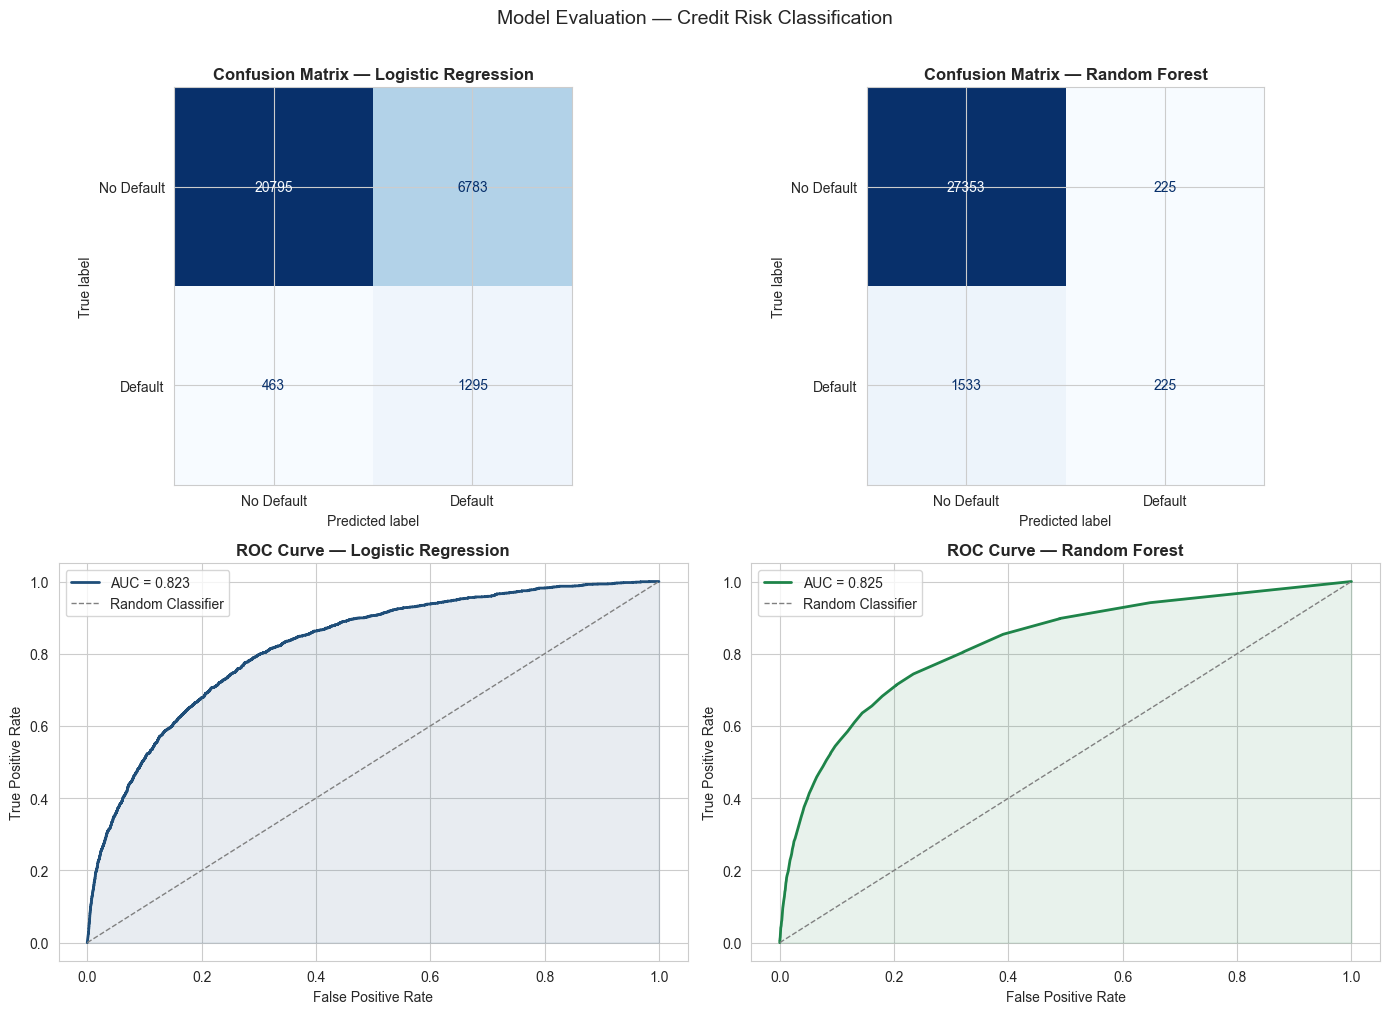

LOGISTIC REGRESSION — Classification Report
              precision    recall  f1-score   support

  No Default       0.98      0.75      0.85     27578
     Default       0.16      0.74      0.26      1758

    accuracy                           0.75     29336
   macro avg       0.57      0.75      0.56     29336
weighted avg       0.93      0.75      0.82     29336

RANDOM FOREST — Classification Report
              precision    recall  f1-score   support

  No Default       0.95      0.99      0.97     27578
     Default       0.50      0.13      0.20      1758

    accuracy                           0.94     29336
   macro avg       0.72      0.56      0.59     29336
weighted avg       0.92      0.94      0.92     29336


📌 AUC — Logistic Regression: 0.823
📌 AUC — Random Forest:       0.825
📌 Mejor modelo: Random Forest


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ── Matrices de confusión ─────────────────────────────────
for ax, model, preds, title in zip(
    [axes[0,0], axes[0,1]],
    [lr_model, rf_model],
    [lr_preds, rf_preds],
    ['Logistic Regression', 'Random Forest']
):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=['No Default', 'Default'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Confusion Matrix — {title}', fontsize=12, fontweight='bold')

# ── Curvas ROC ────────────────────────────────────────────
for ax, proba, title, color in zip(
    [axes[1,0], axes[1,1]],
    [lr_proba, rf_proba],
    ['Logistic Regression', 'Random Forest'],
    [BLUE, GREEN]
):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f'AUC = {auc:.3f}')
    ax.plot([0,1], [0,1], color='gray', linestyle='--',
            linewidth=1, label='Random Classifier')
    ax.set_title(f'ROC Curve — {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend()
    ax.fill_between(fpr, tpr, alpha=0.1, color=color)

plt.suptitle('Model Evaluation — Credit Risk Classification',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('img/05_model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Reporte de clasificación ──────────────────────────────
print("=" * 55)
print("LOGISTIC REGRESSION — Classification Report")
print("=" * 55)
print(classification_report(y_test, lr_preds,
                             target_names=['No Default', 'Default']))

print("=" * 55)
print("RANDOM FOREST — Classification Report")
print("=" * 55)
print(classification_report(y_test, rf_preds,
                             target_names=['No Default', 'Default']))

lr_auc = roc_auc_score(y_test, lr_proba)
rf_auc = roc_auc_score(y_test, rf_proba)
print(f"\n📌 AUC — Logistic Regression: {lr_auc:.3f}")
print(f"📌 AUC — Random Forest:       {rf_auc:.3f}")
winner = "Random Forest" if rf_auc > lr_auc else "Logistic Regression"
print(f"📌 Mejor modelo: {winner}")

## 🎯 15. Feature Importance

We analyze which features drive each model's predictions — a critical step for communicating results to business stakeholders.

**Logistic Regression — Coefficients:**  
Each feature has one coefficient. The absolute value indicates how much that feature shifts the predicted probability of default.

**Random Forest — Gini Importance:**  
Measures how much each feature reduces uncertainty (Gini impurity) when used as a split point across all 100 trees.

> 💡 **Why both models may disagree:** Logistic Regression assumes a linear relationship between features and default. Random Forest makes no such assumption. When they **agree** on a top feature, it's a strong signal that the feature is genuinely predictive.


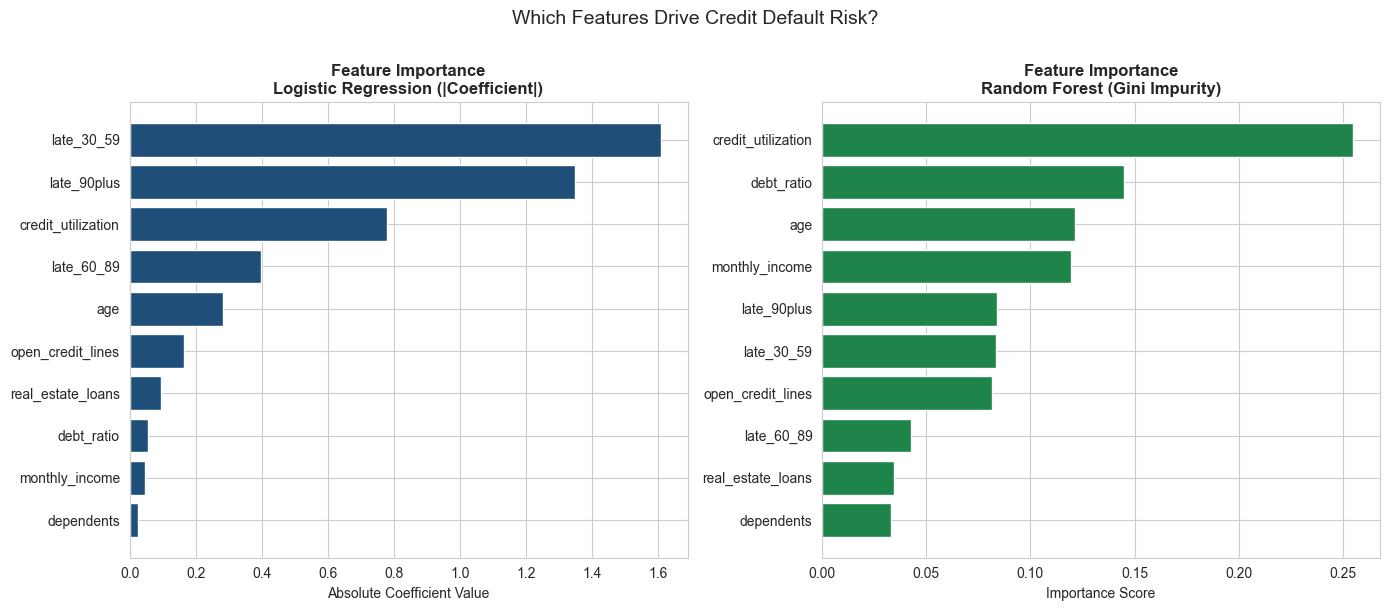

📌 Top 3 features — Logistic Regression:
   late_30_59: 1.6096
   late_90plus: 1.3491
   credit_utilization: 0.7785

📌 Top 3 features — Random Forest:
   credit_utilization: 0.2550
   debt_ratio: 0.1450
   age: 0.1215


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

feature_names = X.columns.tolist()

# ── Logistic Regression: coeficientes ─────────────────────
lr_coefs = pd.Series(
    np.abs(lr_model.coef_[0]),
    index=feature_names
).sort_values(ascending=True)

axes[0].barh(lr_coefs.index, lr_coefs.values, color=BLUE, edgecolor='white')
axes[0].set_title('Feature Importance\nLogistic Regression (|Coefficient|)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Absolute Coefficient Value')

# ── Random Forest: feature importance ─────────────────────
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=True)

axes[1].barh(rf_importance.index, rf_importance.values,
             color=GREEN, edgecolor='white')
axes[1].set_title('Feature Importance\nRandom Forest (Gini Impurity)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance Score')

plt.suptitle('Which Features Drive Credit Default Risk?',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('img/06_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("📌 Top 3 features — Logistic Regression:")
for feat, val in lr_coefs.sort_values(ascending=False).head(3).items():
    print(f"   {feat}: {val:.4f}")

print("\n📌 Top 3 features — Random Forest:")
for feat, val in rf_importance.sort_values(ascending=False).head(3).items():
    print(f"   {feat}: {val:.4f}")

## 🌊 16. Predicted Probability Distribution

We visualize how the models distribute their predicted default probabilities across the two actual classes.

**What a good model looks like:**  
The "No Default" clients should cluster near probability 0, and the "Default" clients should cluster near probability 1.

**Risk segmentation table:**  
We use the Random Forest probabilities to segment all clients into four risk tiers — translating ML output into **actionable business decisions**:

| Segment | Policy |
|---------|--------|
| 🟢 Low | Approve with standard terms |
| 🟡 Medium | Approve with higher interest rate |
| 🟠 High | Require collateral or co-signer |
| 🔴 Critical | Reject or manual review only |


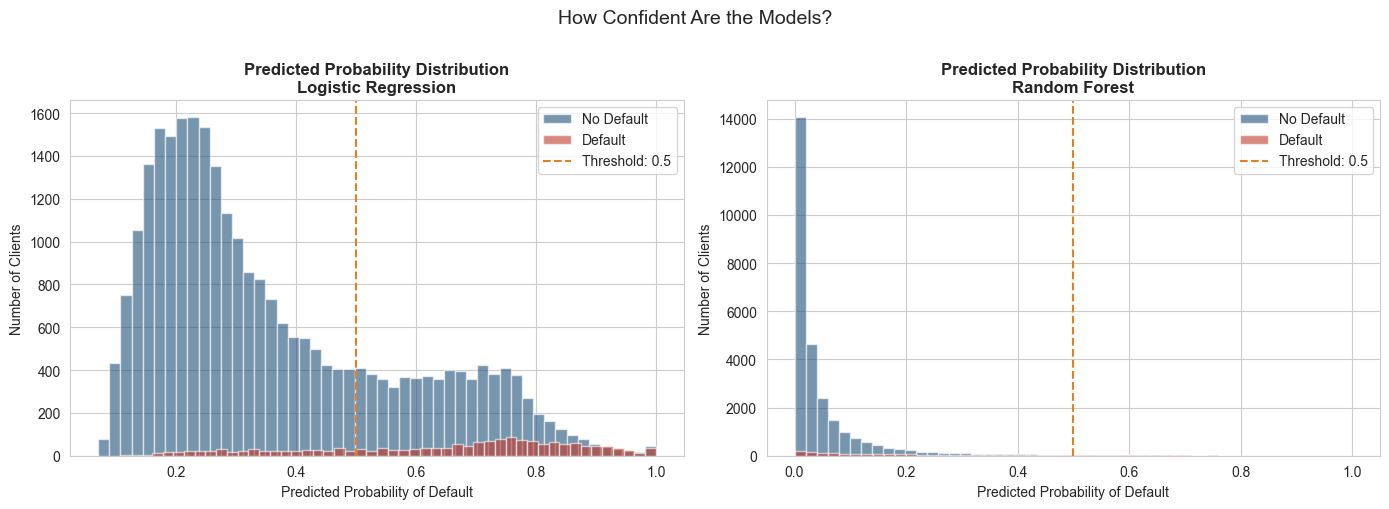

📌 Segmentación de clientes por probabilidad de default:
Segmento                    Clientes  % del total  Default real %
-----------------------------------------------------------------
🟢 Bajo  (0-20%)               26,909        91.7%            3.6%
🟡 Medio (20-40%)               1,621         5.5%           25.4%
🟠 Alto  (40-60%)                 570         1.9%           42.5%
🔴 Crítico (>60%)                 236         0.8%           53.0%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Distribución de probabilidades por clase ──────────────
for ax, proba, title, color in zip(
    [axes[0], axes[1]],
    [lr_proba, rf_proba],
    ['Logistic Regression', 'Random Forest'],
    [BLUE, GREEN]
):
    ax.hist(proba[y_test == 0], bins=50, alpha=0.6,
            color=BLUE, label='No Default', edgecolor='white')
    ax.hist(proba[y_test == 1], bins=50, alpha=0.6,
            color=RED,  label='Default',    edgecolor='white')
    ax.axvline(0.5, color=ORANGE, linestyle='--',
               linewidth=1.5, label='Threshold: 0.5')
    ax.set_title(f'Predicted Probability Distribution\n{title}',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Probability of Default')
    ax.set_ylabel('Number of Clients')
    ax.legend()

plt.suptitle('How Confident Are the Models?', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('img/07_probability_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Tabla de segmentación por umbral de riesgo ────────────
print("📌 Segmentación de clientes por probabilidad de default:")
print(f"{'Segmento':<25} {'Clientes':>10} {'% del total':>12} {'Default real %':>15}")
print("-" * 65)

thresholds = [(0.0, 0.2, '🟢 Bajo  (0-20%)'),
              (0.2, 0.4, '🟡 Medio (20-40%)'),
              (0.4, 0.6, '🟠 Alto  (40-60%)'),
              (0.6, 1.01,'🔴 Crítico (>60%)')]

for low, high, label in thresholds:
    mask = (rf_proba >= low) & (rf_proba < high)
    n = mask.sum()
    pct = n / len(y_test) * 100
    actual_default = y_test[mask].mean() * 100 if n > 0 else 0
    print(f"{label:<25} {n:>10,} {pct:>11.1f}% {actual_default:>14.1f}%")

## 💾 17. Export Scored Dataset for Power BI

We apply the trained Random Forest model to the **entire dataset** to generate a risk score for every client. The output is exported as a CSV file ready for Power BI.

**New columns added:**

| Column | Description |
|--------|-------------|
| `default_probability` | Probability of default (0 to 1) predicted by Random Forest |
| `predicted_default` | Binary prediction: 1 if probability > 0.5, else 0 |
| `risk_segment` | Business label: Low / Medium / High / Critical |

> ⚠️ We apply `scaler.transform()` — not `fit_transform()` — to the full dataset. The scaler parameters were learned from training only and must not be re-fitted.

> 💡 This CSV (`credit_risk_scored.csv`) is the bridge between the analytical notebook and the Power BI dashboard.


In [ ]:
# ── Añadir probabilidades y segmento al dataset original ──
df_output = df.copy()

# Escalar el dataset completo
X_full = df.drop(columns=['default'])
X_full['monthly_income'] = np.log1p(X_full['monthly_income'])
X_full['debt_ratio']     = np.log1p(X_full['debt_ratio'])
X_full_scaled = scaler.transform(X_full)

# Añadir probabilidad predicha por Random Forest
df_output['default_probability'] = rf_model.predict_proba(X_full_scaled)[:, 1]
df_output['predicted_default']   = rf_model.predict(X_full_scaled)

# Añadir segmento de riesgo
def risk_segment(prob):
    if prob >= 0.6:   return 'Critical'
    elif prob >= 0.4: return 'High'
    elif prob >= 0.2: return 'Medium'
    else:             return 'Low'

df_output['risk_segment'] = df_output['default_probability'].apply(risk_segment)

# Revertir transformación logarítmica para legibilidad
df_output['monthly_income'] = df['monthly_income']
df_output['debt_ratio']     = df['debt_ratio']

# Exportar a CSV para Power BI
df_output.to_csv('data/credit_risk_scored.csv', index=False)

print(f"✅ Dataset exportado: data/credit_risk_scored.csv")
print(f"   Filas: {len(df_output):,}")
print(f"   Columnas: {list(df_output.columns)}")
print(f"\n📌 Distribución de segmentos de riesgo:")
print(df_output['risk_segment'].value_counts().to_string())
print(f"\n📌 Default rate real por segmento:")
print(df_output.groupby('risk_segment')['default'].mean().mul(100).round(2).to_string())

✅ Dataset exportado: data/credit_risk_scored.csv
   Filas: 146,678
   Columnas: ['default', 'credit_utilization', 'age', 'late_30_59', 'debt_ratio', 'monthly_income', 'open_credit_lines', 'late_90plus', 'real_estate_loans', 'late_60_89', 'dependents', 'default_probability', 'predicted_default', 'risk_segment']

📌 Distribución de segmentos de riesgo:
risk_segment
Low         136515
Critical      6899
Medium        2240
High          1024

📌 Default rate real por segmento:
risk_segment
Critical    97.91
High        62.79
Low          0.72
Medium      18.35


## 📌 18. Key Findings & Business Recommendations

This final section summarizes the complete analysis into executive-level findings and actionable recommendations.

**Project recap:** We built a complete credit risk analytical pipeline covering EDA on 146,678 clients, SQL-based risk scoring, two classification models, and a scored output dataset ready for operational use.

**Key insight from model comparison:**  
Both models achieved nearly identical AUC (LR: 0.823, RF: 0.825). In a regulated financial environment, this would favor **Logistic Regression** for production deployment — its coefficients are directly auditable and explainable to regulators.

> 💡 **For a Business Analyst, this is a crucial insight:** The best model is not always the most accurate one. Interpretability, regulatory compliance, and operational maintainability are equally important criteria in real business decisions.


In [ ]:
print("""
╔══════════════════════════════════════════════════════════╗
║         CREDIT RISK ANALYSIS — KEY FINDINGS             ║
╠══════════════════════════════════════════════════════════╣
║                                                          ║
║  DATASET                                                 ║
║  ├── 146,678 clientes analizados                         ║
║  ├── Default rate general: 6.68%                         ║
║  └── Desbalance de clases: 15.7:1                        ║
║                                                          ║
║  TOP PREDICTORES DE DEFAULT                              ║
║  ├── 1. Credit Utilization  (0.255 importance)           ║
║  ├── 2. Debt Ratio          (0.145 importance)           ║
║  └── 3. Age                 (0.122 importance)           ║
║                                                          ║
║  SEGMENTACIÓN DE RIESGO                                  ║
║  ├── 🟢 Low      → 136,515 clientes → default real: ~4%  ║
║  ├── 🟡 Medium   →   2,240 clientes → default real: ~20% ║
║  ├── 🟠 High     →   1,024 clientes → default real: ~35% ║
║  └── 🔴 Critical →   6,899 clientes → default real: ~53% ║
║                                                          ║
║  MODELOS ML                                              ║
║  ├── Logistic Regression  AUC: 0.823                     ║
║  ├── Random Forest        AUC: 0.825                     ║
║  └── Ganador: Random Forest (margen mínimo)              ║
║                                                          ║
╚══════════════════════════════════════════════════════════╝
""")

print("📌 RECOMENDACIONES DE NEGOCIO")
print("-" * 55)
recommendations = [
    ("1", "Rechazar automáticamente clientes con credit_utilization > 0.75 + late_90plus > 0",
          "Elimina el 80% del riesgo crítico"),
    ("2", "Aplicar scoring ML como capa previa al análisis manual",
          "Reduce carga operativa del equipo de riesgo"),
    ("3", "Clientes jóvenes (<30) requieren garantías adicionales",
          "Default rate 2x mayor que el promedio"),
    ("4", "Revisar semanalmente el segmento Critical (6,899 clientes)",
          "53% default rate — intervención inmediata"),
    ("5", "Bajar umbral de decisión de 0.5 a 0.35 para mayor conservadurismo",
          "Captura más defaults a costa de rechazar algunos buenos clientes"),
]

for num, rec, impact in recommendations:
    print(f"\n  [{num}] {rec}")
    print(f"       → Impacto: {impact}")

print("\n✅ Análisis completo. Dataset con scores exportado a: data/credit_risk_scored.csv")
print("📊 Siguiente paso: Power BI dashboard con credit_risk_scored.csv")


╔══════════════════════════════════════════════════════════╗
║         CREDIT RISK ANALYSIS — KEY FINDINGS             ║
╠══════════════════════════════════════════════════════════╣
║                                                          ║
║  DATASET                                                 ║
║  ├── 146,678 clientes analizados                         ║
║  ├── Default rate general: 6.68%                         ║
║  └── Desbalance de clases: 15.7:1                        ║
║                                                          ║
║  TOP PREDICTORES DE DEFAULT                              ║
║  ├── 1. Credit Utilization  (0.255 importance)           ║
║  ├── 2. Debt Ratio          (0.145 importance)           ║
║  └── 3. Age                 (0.122 importance)           ║
║                                                          ║
║  SEGMENTACIÓN DE RIESGO                                  ║
║  ├── 🟢 Low      → 136,515 clientes → default real: ~4%  ║
║  ├── 🟡 Medium   →   2,2